# Calibração de câmeras pelo método de Zhang

Este notebook implementa o procedimento descrito por Zhengyou Zhang em **“A Flexible New Technique for Camera Calibration”** (Microsoft Research, MSR-TR-98-71).

Referência:

Z. Zhang, *A Flexible New Technique for Camera Calibration*, Microsoft Research Technical Report MSR-TR-98-71.  
https://www.microsoft.com/en-us/research/wp-content/uploads/2016/02/tr98-71.pdf

A sequência segue a Seção 3.4 do artigo:

1. utilizar um padrão plano;
2. obter imagens do padrão sob diferentes orientações;
3. detectar os pontos característicos;
4. estimar os cinco parâmetros intrínsecos e todos os parâmetros extrínsecos pela solução fechada da Seção 3.1;
5. estimar os dois coeficientes de distorção radial por mínimos quadrados lineares, conforme a Equação (13);
6. refinar conjuntamente todos os parâmetros minimizando a Equação (14) por Levenberg–Marquardt.

A estimação de cada homografia segue o Apêndice A: uma solução linear fornece a inicialização, seguida de refinamento por máxima verossimilhança.

O OpenCV é utilizado para leitura auxiliar das imagens, detecção dos cantos do padrão, visualização e conversão entre matriz de rotação e vetor de Rodrigues. As etapas de calibração são implementadas explicitamente a partir das equações do artigo.

## 1. Configuração do experimento

O padrão utilizado é um tabuleiro plano com **9 × 6 cantos internos**. O lado de cada quadrado impresso foi medido como **25 mm**.

As imagens devem estar organizadas como:

```text
images/
├── iphone15/
└── ipad9/
```

O notebook descobre automaticamente todos os arquivos de imagem suportados existentes diretamente nessas duas pastas. Não há uma lista manual de fotografias.

Todas as imagens de uma mesma câmera devem apresentar a mesma resolução e orientação após a aplicação dos metadados EXIF. Caso sejam encontrados sistemas de coordenadas de imagem incompatíveis, a execução é interrompida.

In [4]:
from __future__ import annotations

import json
import math
import platform
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image, ImageOps
from scipy.optimize import least_squares

try:
    from pillow_heif import register_heif_opener
    register_heif_opener()
    HEIF_SUPPORT = True
except ImportError:
    HEIF_SUPPORT = False

np.set_printoptions(precision=8, suppress=True)

print(f"Python: {platform.python_version()}")
print(f"OpenCV: {cv2.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"Suporte a HEIC/HEIF: {HEIF_SUPPORT}")

Python: 3.13.5
OpenCV: 5.0.0
NumPy: 2.5.3
Pandas: 3.0.6
Suporte a HEIC/HEIF: True


In [7]:
CAMERAS = {
    "iphone15": "Apple iPhone 15",
    "ipad9": "Apple iPad (9ª geração)",
}

PATTERN_SIZE = (9, 6)
SQUARE_SIZE_MM = 25.0

SUPPORTED_EXTENSIONS = {
    ".heic", ".heif",
    ".jpg", ".jpeg",
    ".png",
    ".tif", ".tiff",
}

STRICT_ALL_IMAGES = True
MAX_PREVIEW_IMAGES = 6

### Dependências

O ambiente pode ser preparado com:

```bash
pip install numpy scipy pandas matplotlib pillow pillow-heif opencv-python jupyter
```

A biblioteca `pillow-heif` é necessária para leitura direta de arquivos `.HEIC` e `.HEIF`.

In [8]:
def find_repository_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()

    for candidate in [start, *start.parents]:
        images_dir = candidate / "images"
        if all((images_dir / camera_id).is_dir() for camera_id in CAMERAS):
            return candidate

    raise FileNotFoundError(
        "Não foi possível localizar a raiz do repositório contendo "
        "images/iphone15/ e images/ipad9/."
    )


ROOT = find_repository_root()
IMAGES_DIR = ROOT / "images"

RESULTS_DIR = ROOT / "results"
CALIBRATION_DIR = RESULTS_DIR / "calibration"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"

for directory in (CALIBRATION_DIR, FIGURES_DIR, TABLES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"Raiz do repositório: {ROOT}")

Raiz do repositório: /Users/gabriellopesbastos/Projects/camera-calibration-zhang


## 2. Detecção dos pontos do padrão

Na notação do artigo, um ponto do plano do modelo é

$$
M_j=[X_j,Y_j]^T,
$$

e o ponto correspondente observado na imagem $i$ é

$$
m_{ij}=[u_{ij},v_{ij}]^T.
$$

O artigo requer a extração dos pontos característicos, mas não impõe um detector específico. Neste experimento, os cantos internos do tabuleiro são detectados com OpenCV.

Uma imagem somente é considerada válida quando todos os **54 cantos internos** são encontrados. Com `STRICT_ALL_IMAGES = True`, nenhuma fotografia é descartada silenciosamente: uma falha de detecção interrompe a execução.

In [9]:
from collections import Counter


def discover_images(folder: Path) -> list[Path]:
    paths = sorted(
        path for path in folder.iterdir()
        if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS
    )

    if not paths:
        raise FileNotFoundError(
            f"Nenhuma imagem suportada foi encontrada em {folder}."
        )

    has_heif = any(
        path.suffix.lower() in {".heic", ".heif"}
        for path in paths
    )

    if has_heif and not HEIF_SUPPORT:
        raise ImportError(
            "Foram encontrados arquivos HEIC/HEIF, mas pillow-heif "
            "não está instalada."
        )

    return paths


def get_oriented_image_size(path: Path) -> tuple[int, int]:
    """
    Obtém a resolução que a imagem apresenta após a aplicação
    da orientação EXIF, sem manter a imagem decodificada na memória.
    """
    with Image.open(path) as image:
        width, height = image.size

        exif = image.getexif()
        orientation = exif.get(274, 1)

        # As orientações EXIF 5, 6, 7 e 8 trocam largura e altura.
        if orientation in {5, 6, 7, 8}:
            width, height = height, width

    return width, height


def load_image(path: Path) -> np.ndarray:
    """
    Carrega uma única imagem, aplica sua orientação EXIF
    e converte o resultado para o formato BGR do OpenCV.
    """
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image)
        rgb = np.asarray(
            image.convert("RGB")
        )

    return cv2.cvtColor(
        rgb,
        cv2.COLOR_RGB2BGR,
    )


def normalize_image_orientation(
    image: np.ndarray,
    reference_size: tuple[int, int],
) -> tuple[np.ndarray, str]:
    """
    Coloca a imagem no mesmo sistema de coordenadas adotado
    para o conjunto daquela câmera.

    A resolução/orientação mais frequente é utilizada como referência.
    Caso largura e altura estejam apenas invertidas, a imagem é
    rotacionada em 90 graus.

    Nenhum redimensionamento é realizado.
    """
    height, width = image.shape[:2]
    current_size = (width, height)

    if current_size == reference_size:
        return image, "original"

    if current_size == reference_size[::-1]:
        rotated = cv2.rotate(
            image,
            cv2.ROTATE_90_CLOCKWISE,
        )

        return rotated, "rotated_90_cw"

    raise ValueError(
        f"Resolução incompatível: {current_size}. "
        f"A resolução de referência é {reference_size}. "
        "A diferença não pode ser corrigida apenas por rotação."
    )


def inspect_dataset(camera_id: str) -> dict:
    folder = IMAGES_DIR / camera_id
    paths = discover_images(folder)

    # Nesta etapa são obtidos apenas os metadados necessários
    # para determinar a resolução/orientação predominante.
    original_sizes = [
        get_oriented_image_size(path)
        for path in paths
    ]

    # A resolução/orientação mais frequente define o sistema
    # de coordenadas utilizado para essa câmera.
    reference_size, reference_count = Counter(
        original_sizes
    ).most_common(1)[0]

    entries = []

    for path, original_size in zip(
        paths,
        original_sizes,
    ):
        if original_size == reference_size:
            normalization = "original"

        elif original_size == reference_size[::-1]:
            normalization = "rotated_90_cw"

        else:
            raise ValueError(
                f"{CAMERAS[camera_id]}: a imagem {path.name} "
                f"possui resolução {original_size}, incompatível "
                f"com a resolução de referência {reference_size}. "
                "A diferença não corresponde apenas a uma mudança "
                "de orientação."
            )

        entries.append({
            "path": path,
            "original_size": original_size,
            "size": reference_size,
            "orientation_normalization": normalization,
        })

    return {
        "camera_id": camera_id,
        "camera_name": CAMERAS[camera_id],
        "folder": folder,
        "image_size": reference_size,
        "reference_size_count": reference_count,
        "entries": entries,
    }


datasets = {
    camera_id: inspect_dataset(camera_id)
    for camera_id in CAMERAS
}


overview_df = pd.DataFrame([
    {
        "camera": data["camera_name"],
        "folder": str(
            data["folder"].relative_to(ROOT)
        ),
        "images": len(data["entries"]),
        "width_px": data["image_size"][0],
        "height_px": data["image_size"][1],
        "reference_orientation_images": (
            data["reference_size_count"]
        ),
        "rotated_images": sum(
            entry["orientation_normalization"] != "original"
            for entry in data["entries"]
        ),
    }
    for data in datasets.values()
])

display(overview_df)

,camera,folder,images,width_px,height_px,reference_orientation_images,rotated_images
0,Apple iPhone 15,images/iphone15,41,4284,5712,35,6
1,Apple iPad (9ª geração),images/ipad9,36,2448,3264,33,3


In [10]:
def detect_chessboard_corners(
    image: np.ndarray,
    pattern_size: tuple[int, int],
) -> tuple[bool, np.ndarray | None, str]:
    """
    Detecta os cantos internos do padrão diretamente na resolução
    original da imagem.

    A detecção é realizada com findChessboardCornersSB. Caso ela
    falhe, utiliza-se o detector clássico como alternativa.

    Quando o detector clássico é utilizado, os pontos são refinados
    em nível subpixel com cornerSubPix.
    """

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY,
    )

    sb_flags = (
        cv2.CALIB_CB_NORMALIZE_IMAGE
        | cv2.CALIB_CB_EXHAUSTIVE
        | cv2.CALIB_CB_ACCURACY
    )

    found, corners = cv2.findChessboardCornersSB(
        gray,
        pattern_size,
        flags=sb_flags,
    )

    if found:
        return (
            True,
            corners.reshape(-1, 2).astype(np.float64),
            "findChessboardCornersSB",
        )

    classic_flags = (
        cv2.CALIB_CB_ADAPTIVE_THRESH
        | cv2.CALIB_CB_NORMALIZE_IMAGE
    )

    found, corners = cv2.findChessboardCorners(
        gray,
        pattern_size,
        flags=classic_flags,
    )

    if not found:
        return (
            False,
            None,
            "not_detected",
        )

    criteria = (
        cv2.TERM_CRITERIA_EPS
        + cv2.TERM_CRITERIA_MAX_ITER,
        50,
        1e-4,
    )

    corners = cv2.cornerSubPix(
        gray,
        corners,
        winSize=(11, 11),
        zeroZone=(-1, -1),
        criteria=criteria,
    )

    return (
        True,
        corners.reshape(-1, 2).astype(np.float64),
        "findChessboardCorners+cornerSubPix",
    )


def detect_dataset(data: dict) -> dict:
    """
    Processa todas as imagens do conjunto sequencialmente.

    Apenas uma fotografia é mantida na memória por vez. Após a
    detecção, a imagem é descartada e somente as coordenadas dos
    cantos permanecem armazenadas.
    """

    entries = []

    total = len(
        data["entries"]
    )

    for index, entry in enumerate(
        data["entries"],
        start=1,
    ):
        print(
            f"\r{data['camera_name']}: "
            f"processando {index}/{total} — "
            f"{entry['path'].name}",
            end="",
        )

        # Carrega apenas uma imagem por vez.
        image = load_image(
            entry["path"]
        )

        # Corrige apenas a orientação quando necessário.
        # Não há redimensionamento.
        image, normalization = (
            normalize_image_orientation(
                image,
                data["image_size"],
            )
        )

        # Detecção na resolução original.
        found, image_points, method = (
            detect_chessboard_corners(
                image,
                PATTERN_SIZE,
            )
        )

        entries.append({
            **entry,
            "orientation_normalization": normalization,
            "pattern_detected": bool(found),
            "image_points": image_points,
            "detection_method": method,
        })

        # A fotografia completa não é armazenada.
        del image

    print()

    return {
        **data,
        "entries": entries,
    }


datasets = {
    camera_id: detect_dataset(data)
    for camera_id, data in datasets.items()
}


detection_rows = []

for data in datasets.values():
    for entry in data["entries"]:
        detection_rows.append({
            "camera_id": data["camera_id"],
            "camera": data["camera_name"],
            "file": entry["path"].name,
            "original_width_px": (
                entry["original_size"][0]
            ),
            "original_height_px": (
                entry["original_size"][1]
            ),
            "orientation_normalization": (
                entry["orientation_normalization"]
            ),
            "pattern_detected": (
                entry["pattern_detected"]
            ),
            "detection_method": (
                entry["detection_method"]
            ),
        })


detection_df = pd.DataFrame(
    detection_rows
)


detection_summary_df = (
    detection_df
    .groupby(
        [
            "camera_id",
            "camera",
        ],
        as_index=False,
    )
    .agg(
        images=(
            "file",
            "count",
        ),
        detected=(
            "pattern_detected",
            "sum",
        ),
    )
)


detection_summary_df["failed"] = (
    detection_summary_df["images"]
    - detection_summary_df["detected"]
)


display(
    detection_summary_df
)


failed_df = detection_df.loc[
    ~detection_df["pattern_detected"]
]


if not failed_df.empty:
    print(
        "Imagens nas quais o padrão "
        "não foi detectado:"
    )

    display(
        failed_df
    )

else:
    print(
        "O padrão foi detectado em "
        "todas as imagens."
    )

Apple iPhone 15: processando 41/41 — IMG_9249.HEIC
Apple iPad (9ª geração): processando 36/36 — IMG_0179.HEIC


,camera_id,camera,images,detected,failed
0,ipad9,Apple iPad (9ª geração),36,36,0
1,iphone15,Apple iPhone 15,41,41,0


O padrão foi detectado em todas as imagens.


In [11]:
if STRICT_ALL_IMAGES and not failed_df.empty:
    raise RuntimeError(
        "A execução foi interrompida porque STRICT_ALL_IMAGES=True "
        "e o padrão não foi detectado em todas as imagens."
    )

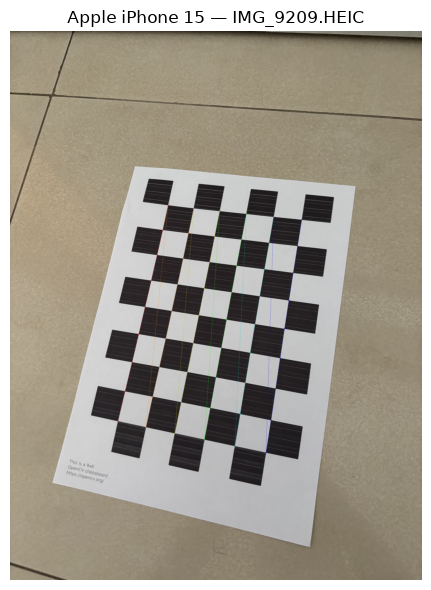

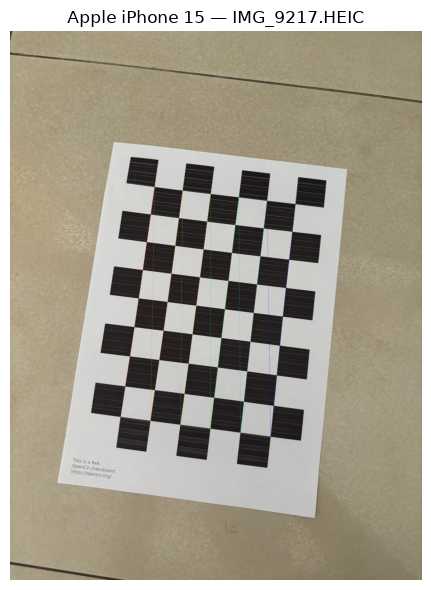

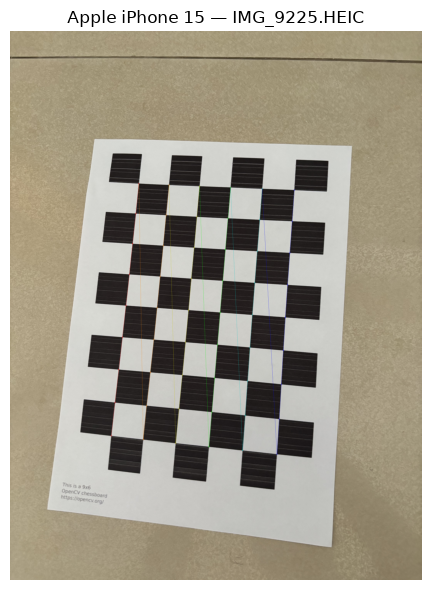

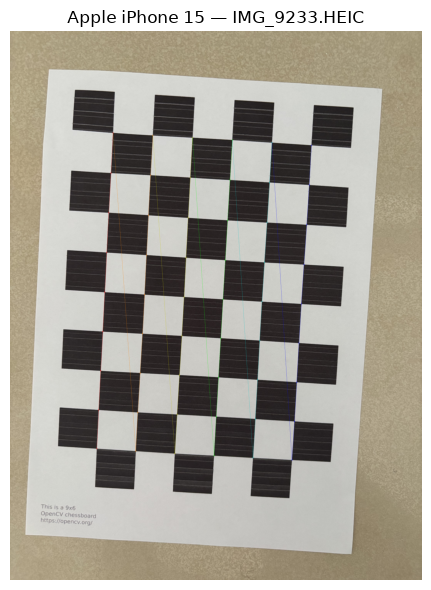

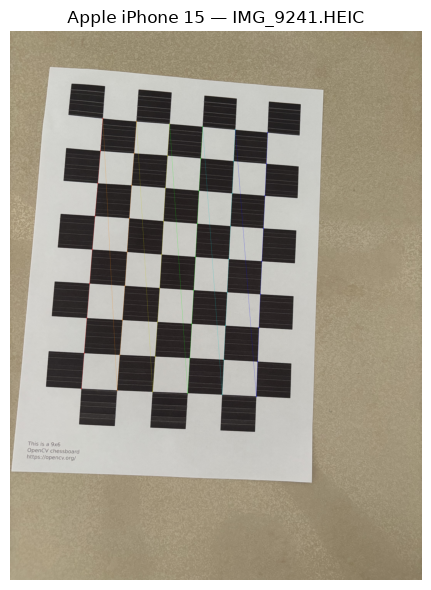

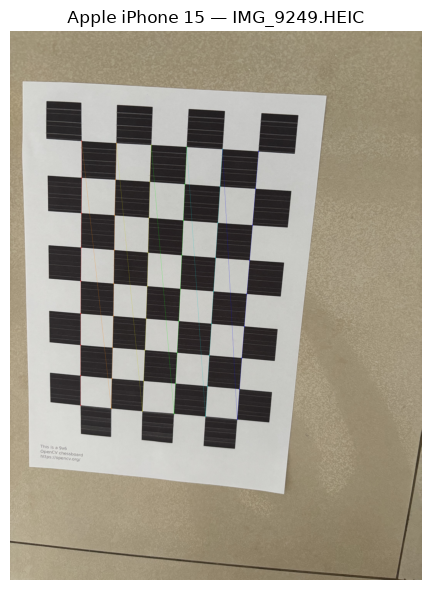

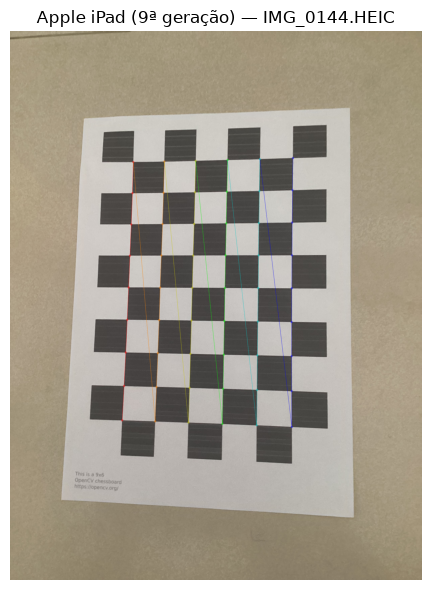

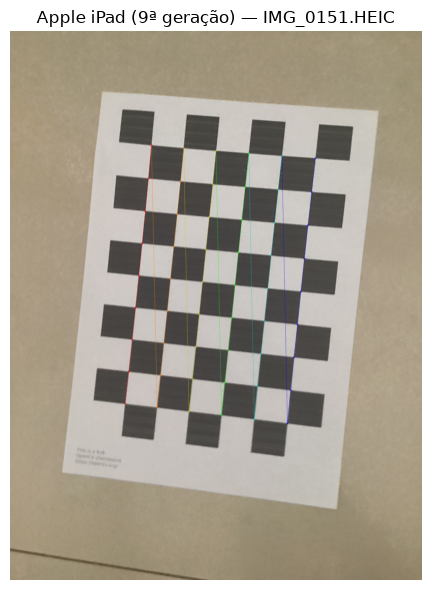

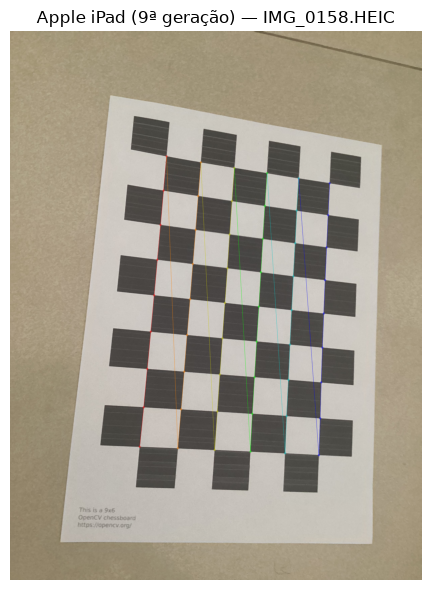

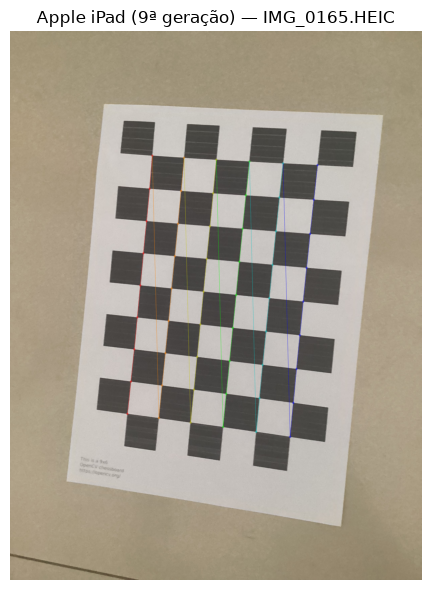

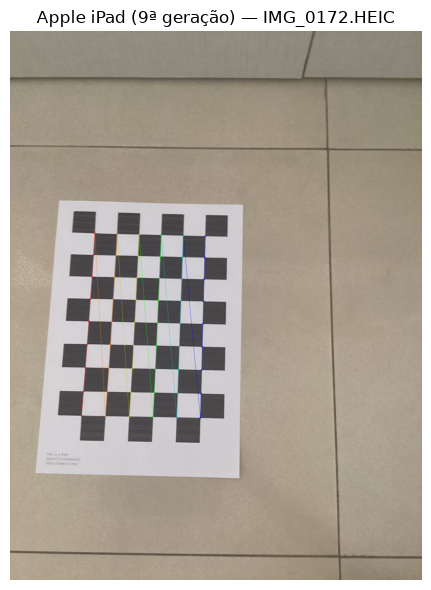

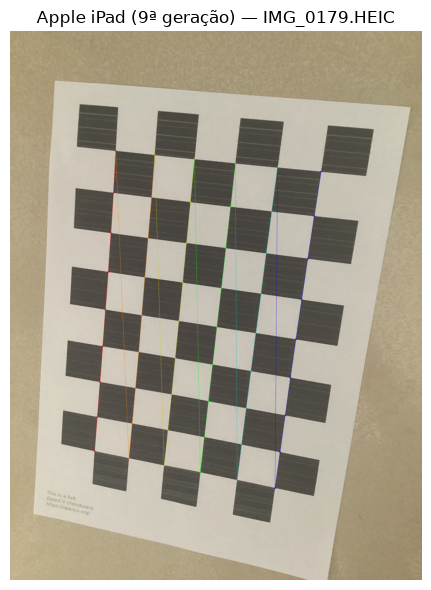

In [12]:
def show_detection_previews(
    data: dict,
    max_images: int = 6,
) -> None:
    """
    Exibe uma amostra das imagens com os cantos detectados.

    As imagens são carregadas individualmente apenas para visualização.
    A detecção dos cantos já foi realizada na resolução original.

    Para reduzir o consumo de memória no notebook, a imagem é
    redimensionada apenas para exibição. Esse redimensionamento não
    altera os pontos detectados nem os dados utilizados na calibração.
    """

    valid_entries = [
        entry
        for entry in data["entries"]
        if entry["pattern_detected"]
    ]

    if not valid_entries:
        print(
            f"Nenhuma detecção válida para "
            f"{data['camera_name']}."
        )
        return

    count = min(
        max_images,
        len(valid_entries),
    )

    # Seleciona imagens distribuídas ao longo do conjunto apenas
    # para inspeção visual. Todas as imagens válidas continuam
    # sendo utilizadas na calibração.
    indices = np.linspace(
        0,
        len(valid_entries) - 1,
        count,
        dtype=int,
    )

    for index in indices:
        entry = valid_entries[index]

        # Carrega apenas uma imagem por vez.
        image = load_image(
            entry["path"]
        )

        # Aplica a mesma normalização de orientação adotada
        # durante a etapa de detecção.
        image, _ = normalize_image_orientation(
            image,
            data["image_size"],
        )

        preview = image.copy()

        corners_for_draw = (
            entry["image_points"]
            .reshape(-1, 1, 2)
            .astype(np.float32)
        )

        # Os cantos são desenhados ainda na resolução original.
        cv2.drawChessboardCorners(
            preview,
            PATTERN_SIZE,
            corners_for_draw,
            True,
        )

        # Redução exclusiva para visualização no notebook.
        # Nenhum dado utilizado na calibração é alterado.
        height, width = preview.shape[:2]
        max_preview_dimension = 1600

        if max(width, height) > max_preview_dimension:
            scale = (
                max_preview_dimension
                / max(width, height)
            )

            preview_width = int(
                round(width * scale)
            )

            preview_height = int(
                round(height * scale)
            )

            preview = cv2.resize(
                preview,
                (
                    preview_width,
                    preview_height,
                ),
                interpolation=cv2.INTER_AREA,
            )

        plt.figure(
            figsize=(8, 6)
        )

        plt.imshow(
            cv2.cvtColor(
                preview,
                cv2.COLOR_BGR2RGB,
            )
        )

        plt.title(
            f"{data['camera_name']} — "
            f"{entry['path'].name}"
        )

        plt.axis("off")
        plt.tight_layout()
        plt.show()

        # Libera explicitamente os buffers gráficos e a imagem
        # para reduzir o consumo de memória do Jupyter.
        plt.close()

        del image
        del preview


for data in datasets.values():
    show_detection_previews(
        data,
        MAX_PREVIEW_IMAGES,
    )

## 3. Coordenadas do plano do modelo

Na Seção 2.2, Zhang assume, sem perda de generalidade, que o padrão está no plano

$$
Z=0.
$$

Assim,

$$
M=[X,Y]^T,
\qquad
\widetilde M=[X,Y,1]^T.
$$

Os 54 cantos internos são representados por coordenadas métricas no plano, com espaçamento de 25 mm.

In [13]:
def create_model_points(
    pattern_size: tuple[int, int],
    square_size_mm: float,
) -> np.ndarray:
    cols, rows = pattern_size

    points = np.mgrid[0:cols, 0:rows].T.reshape(-1, 2)
    points = points.astype(np.float64)
    points *= square_size_mm

    return points


MODEL_POINTS = create_model_points(
    PATTERN_SIZE,
    SQUARE_SIZE_MM,
)

print(f"Número de pontos do modelo: {len(MODEL_POINTS)}")
print(MODEL_POINTS[:5])

Número de pontos do modelo: 54
[[  0.   0.]
 [ 25.   0.]
 [ 50.   0.]
 [ 75.   0.]
 [100.   0.]]


## 4. Homografia entre o plano do modelo e a imagem

A Equação (2) estabelece

$$
s\widetilde m
=
H\widetilde M,
\qquad
H=A[r_1\ r_2\ t].
$$

Cada vista fornece uma homografia $H$, definida a menos de escala.

### 4.1 Inicialização linear — Apêndice A

Para cada correspondência $(X,Y)\leftrightarrow(u,v)$, o Apêndice A constrói duas equações lineares. Com $n$ pontos:

$$
Lx=0,
\qquad
L\in\mathbb{R}^{2n\times9}.
$$

A solução é o vetor singular direito de $L$ associado ao menor valor singular.

O Apêndice A observa que $L$ pode ser mal condicionada e recomenda normalização dos dados antes da solução linear, citando o procedimento de Hartley. Como o artigo não fixa uma transformação única, emprega-se aqui a normalização isotrópica padrão: centroide na origem e distância média ao centro igual a $\sqrt{2}$.

### 4.2 Refinamento por máxima verossimilhança

Assumindo ruído gaussiano independente e de mesma variância nos pontos de imagem, o Apêndice A minimiza

$$
\sum_j \|m_j-\widehat m_j\|^2.
$$

A solução linear normalizada é utilizada como inicialização e a homografia é refinada por Levenberg–Marquardt.

In [14]:
def normalize_points_2d(
    points: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    centroid = np.mean(points, axis=0)
    centered = points - centroid

    mean_distance = np.mean(
        np.linalg.norm(centered, axis=1)
    )

    if mean_distance <= np.finfo(float).eps:
        raise ValueError(
            "Não é possível normalizar um conjunto de pontos degenerado."
        )

    scale = math.sqrt(2.0) / mean_distance

    T = np.array([
        [scale, 0.0, -scale * centroid[0]],
        [0.0, scale, -scale * centroid[1]],
        [0.0, 0.0, 1.0],
    ])

    homogeneous = np.column_stack([
        points,
        np.ones(len(points)),
    ])

    normalized_h = (T @ homogeneous.T).T
    normalized = normalized_h[:, :2] / normalized_h[:, 2:3]

    return normalized, T


def build_homography_system(
    model_points: np.ndarray,
    image_points: np.ndarray,
) -> np.ndarray:
    rows = []

    for (X, Y), (u, v) in zip(model_points, image_points):
        M = np.array([X, Y, 1.0])

        rows.append(
            np.concatenate([M, np.zeros(3), -u * M])
        )
        rows.append(
            np.concatenate([np.zeros(3), M, -v * M])
        )

    return np.asarray(rows, dtype=np.float64)


def estimate_homography_linear(
    model_points: np.ndarray,
    image_points: np.ndarray,
) -> np.ndarray:
    model_n, T_model = normalize_points_2d(model_points)
    image_n, T_image = normalize_points_2d(image_points)

    L = build_homography_system(
        model_n,
        image_n,
    )

    _, _, Vt = np.linalg.svd(L)
    h = Vt[-1]

    H_n = h.reshape(3, 3)

    H = (
        np.linalg.inv(T_image)
        @ H_n
        @ T_model
    )

    if abs(H[2, 2]) <= np.finfo(float).eps:
        H /= np.linalg.norm(H)
    else:
        H /= H[2, 2]

    return H


def apply_homography(
    H: np.ndarray,
    model_points: np.ndarray,
) -> np.ndarray:
    homogeneous = np.column_stack([
        model_points,
        np.ones(len(model_points)),
    ])

    projected_h = (H @ homogeneous.T).T

    return projected_h[:, :2] / projected_h[:, 2:3]


def homography_to_parameters(H: np.ndarray) -> np.ndarray:
    H = H / H[2, 2]

    return np.array([
        H[0, 0], H[0, 1], H[0, 2],
        H[1, 0], H[1, 1], H[1, 2],
        H[2, 0], H[2, 1],
    ])


def parameters_to_homography(parameters: np.ndarray) -> np.ndarray:
    return np.array([
        [parameters[0], parameters[1], parameters[2]],
        [parameters[3], parameters[4], parameters[5]],
        [parameters[6], parameters[7], 1.0],
    ])


def refine_homography(
    H_initial: np.ndarray,
    model_points: np.ndarray,
    image_points: np.ndarray,
) -> tuple[np.ndarray, object]:
    p0 = homography_to_parameters(H_initial)

    def residuals(parameters: np.ndarray) -> np.ndarray:
        H = parameters_to_homography(parameters)
        projected = apply_homography(H, model_points)
        return (projected - image_points).ravel()

    result = least_squares(
        residuals,
        p0,
        method="lm",
        x_scale="jac",
        max_nfev=2000,
    )

    H = parameters_to_homography(result.x)
    H /= H[2, 2]

    return H, result

In [15]:
def estimate_view_homographies(data: dict) -> dict:
    valid_entries = [
        entry for entry in data["entries"]
        if entry["pattern_detected"]
    ]

    homographies = []
    diagnostics = []

    for entry in valid_entries:
        H_linear = estimate_homography_linear(
            MODEL_POINTS,
            entry["image_points"],
        )

        linear_projection = apply_homography(
            H_linear,
            MODEL_POINTS,
        )

        linear_rmse = np.sqrt(np.mean(
            np.sum(
                (linear_projection - entry["image_points"]) ** 2,
                axis=1,
            )
        ))

        H_refined, result = refine_homography(
            H_linear,
            MODEL_POINTS,
            entry["image_points"],
        )

        refined_projection = apply_homography(
            H_refined,
            MODEL_POINTS,
        )

        refined_rmse = np.sqrt(np.mean(
            np.sum(
                (refined_projection - entry["image_points"]) ** 2,
                axis=1,
            )
        ))

        homographies.append(H_refined)

        diagnostics.append({
            "file": entry["path"].name,
            "linear_homography_rmse_px": float(linear_rmse),
            "refined_homography_rmse_px": float(refined_rmse),
            "lm_success": bool(result.success),
            "lm_nfev": int(result.nfev),
        })

    return {
        **data,
        "valid_entries": valid_entries,
        "homographies": homographies,
        "homography_diagnostics": pd.DataFrame(diagnostics),
    }


datasets = {
    camera_id: estimate_view_homographies(data)
    for camera_id, data in datasets.items()
}

for data in datasets.values():
    print(data["camera_name"])
    display(data["homography_diagnostics"])

Apple iPhone 15


,file,linear_homography_rmse_px,refined_homography_rmse_px,lm_success,lm_nfev
0,IMG_9209.HEIC,2.707403,2.703167,True,4
1,IMG_9210.HEIC,2.890374,2.886225,True,4
2,IMG_9211.HEIC,2.781361,2.779737,True,4
3,IMG_9212.HEIC,2.764233,2.763175,True,4
4,IMG_9213.HEIC,2.714393,2.714225,True,3
5,IMG_9214.HEIC,2.412556,2.412276,True,3
6,IMG_9215.HEIC,2.895161,2.889205,True,4
7,IMG_9216.HEIC,2.766210,2.763420,True,4
8,IMG_9217.HEIC,2.909487,2.907961,True,4
9,IMG_9218.HEIC,2.380925,2.380013,True,4


Apple iPad (9ª geração)


,file,linear_homography_rmse_px,refined_homography_rmse_px,lm_success,lm_nfev
0,IMG_0144.HEIC,1.639731,1.638936,True,4
1,IMG_0145.HEIC,1.312208,1.311589,True,4
2,IMG_0146.HEIC,0.901236,0.900855,True,3
3,IMG_0147.HEIC,1.415151,1.414875,True,3
4,IMG_0148.HEIC,0.970618,0.969273,True,4
5,IMG_0149.HEIC,1.374683,1.370308,True,4
6,IMG_0150.HEIC,1.284147,1.278913,True,4
7,IMG_0151.HEIC,1.693256,1.693195,True,3
8,IMG_0152.HEIC,1.521248,1.520967,True,3
9,IMG_0153.HEIC,1.565160,1.564983,True,3


## 5. Solução fechada dos parâmetros intrínsecos — Seção 3.1

Zhang define

$$
A=
\begin{bmatrix}
\alpha & \gamma & u_0\\
0 & \beta & v_0\\
0 & 0 & 1
\end{bmatrix}
$$

e

$$
B=A^{-T}A^{-1}.
$$

Como $B$ é simétrica:

$$
b=
[B_{11},B_{12},B_{22},B_{13},B_{23},B_{33}]^T.
$$

Para

$$
H=[h_1\ h_2\ h_3],
$$

as Equações (3) e (4) são

$$
h_1^T B h_2=0
$$

e

$$
h_1^T B h_1=h_2^T B h_2.
$$

A Equação (7) define

$$
v_{ij}=
[
h_{i1}h_{j1},
h_{i1}h_{j2}+h_{i2}h_{j1},
h_{i2}h_{j2},
h_{i3}h_{j1}+h_{i1}h_{j3},
h_{i3}h_{j2}+h_{i2}h_{j3},
h_{i3}h_{j3}
]^T.
$$

Cada vista fornece, pela Equação (8),

$$
\begin{bmatrix}
v_{12}^T\\
(v_{11}-v_{22})^T
\end{bmatrix}b=0.
$$

Empilhando todas as vistas:

$$
Vb=0.
$$

Para $n\geq3$, a solução é o vetor singular direito de $V$ associado ao menor valor singular.

In [16]:
def v_ij(
    H: np.ndarray,
    i: int,
    j: int,
) -> np.ndarray:
    hi = H[:, i]
    hj = H[:, j]

    return np.array([
        hi[0] * hj[0],
        hi[0] * hj[1] + hi[1] * hj[0],
        hi[1] * hj[1],
        hi[2] * hj[0] + hi[0] * hj[2],
        hi[2] * hj[1] + hi[1] * hj[2],
        hi[2] * hj[2],
    ])


def build_V(
    homographies: list[np.ndarray],
) -> np.ndarray:
    rows = []

    for H in homographies:
        rows.append(v_ij(H, 0, 1))
        rows.append(
            v_ij(H, 0, 0)
            - v_ij(H, 1, 1)
        )

    return np.asarray(rows, dtype=np.float64)


def solve_b(
    homographies: list[np.ndarray],
) -> tuple[np.ndarray, np.ndarray]:
    if len(homographies) < 3:
        raise ValueError(
            "A solução geral dos cinco parâmetros intrínsecos "
            "requer pelo menos três vistas."
        )

    V = build_V(homographies)

    _, singular_values, Vt = np.linalg.svd(V)
    b = Vt[-1]

    return b, singular_values

### Extração dos parâmetros intrínsecos — Apêndice B

O Apêndice B fornece:

$$
v_0=
\frac{B_{12}B_{13}-B_{11}B_{23}}
{B_{11}B_{22}-B_{12}^2},
$$

$$
\lambda=
B_{33}
-
\frac{
B_{13}^2+
v_0(B_{12}B_{13}-B_{11}B_{23})
}{B_{11}},
$$

$$
\alpha=\sqrt{\frac{\lambda}{B_{11}}},
\qquad
\beta=
\sqrt{
\frac{\lambda B_{11}}
{B_{11}B_{22}-B_{12}^2}
},
$$

$$
\gamma=
-\frac{B_{12}\alpha^2\beta}{\lambda},
$$

$$
u_0=
\frac{\gamma v_0}{\beta}
-
\frac{B_{13}\alpha^2}{\lambda}.
$$

Como $b$ é uma solução homogênea, $b$ e $-b$ são equivalentes. A implementação escolhe o sinal que produz os radicandos positivos exigidos pelas expressões do Apêndice B.

In [17]:
def extract_intrinsics_from_b(
    b: np.ndarray,
) -> tuple[np.ndarray, dict]:
    errors = []

    for sign in (1.0, -1.0):
        candidate = sign * b
        B11, B12, B22, B13, B23, B33 = candidate

        try:
            denominator = B11 * B22 - B12 ** 2

            if abs(B11) <= np.finfo(float).eps:
                raise ValueError("B11 numericamente nulo.")

            if denominator <= 0:
                raise ValueError(
                    "B11*B22 - B12^2 não é positivo."
                )

            v0 = (
                B12 * B13 - B11 * B23
            ) / denominator

            lam = (
                B33
                - (
                    B13 ** 2
                    + v0 * (
                        B12 * B13
                        - B11 * B23
                    )
                ) / B11
            )

            if lam / B11 <= 0:
                raise ValueError("lambda/B11 não é positivo.")

            if lam * B11 / denominator <= 0:
                raise ValueError(
                    "lambda*B11/(B11*B22-B12^2) não é positivo."
                )

            alpha = math.sqrt(lam / B11)
            beta = math.sqrt(
                lam * B11 / denominator
            )

            gamma = (
                -B12
                * alpha ** 2
                * beta
                / lam
            )

            u0 = (
                gamma * v0 / beta
                - B13 * alpha ** 2 / lam
            )

            A = np.array([
                [alpha, gamma, u0],
                [0.0, beta, v0],
                [0.0, 0.0, 1.0],
            ])

            return A, {
                "alpha": float(alpha),
                "beta": float(beta),
                "gamma": float(gamma),
                "u0": float(u0),
                "v0": float(v0),
                "lambda": float(lam),
                "b_sign": int(sign),
            }

        except ValueError as exc:
            errors.append(str(exc))

    raise ValueError(
        "Não foi possível extrair parâmetros intrínsecos reais. "
        + " | ".join(errors)
    )

## 6. Parâmetros extrínsecos — Seção 3.1 e Apêndice C

Uma vez conhecida $A$,

$$
r_1=\lambda A^{-1}h_1,
\qquad
r_2=\lambda A^{-1}h_2,
$$

$$
r_3=r_1\times r_2,
\qquad
t=\lambda A^{-1}h_3,
$$

com

$$
\lambda
=
\frac{1}{\|A^{-1}h_1\|}
=
\frac{1}{\|A^{-1}h_2\|}.
$$

Devido ao ruído, a matriz

$$
Q=[r_1\ r_2\ r_3]
$$

não satisfaz perfeitamente as propriedades de uma matriz de rotação.

O Apêndice C determina a aproximação de rotação mais próxima. Se

$$
Q=U\Sigma V^T,
$$

então

$$
R=UV^T.
$$

In [18]:
def nearest_rotation_matrix(Q: np.ndarray) -> np.ndarray:
    U, _, Vt = np.linalg.svd(Q)
    return U @ Vt


def extrinsics_from_homography(
    A: np.ndarray,
    H: np.ndarray,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    A_inv = np.linalg.inv(A)
    H_work = H.copy()

    a1 = A_inv @ H_work[:, 0]
    a2 = A_inv @ H_work[:, 1]
    a3 = A_inv @ H_work[:, 2]

    lam = 1.0 / np.linalg.norm(a1)

    r1 = lam * a1
    r2 = lam * a2
    r3 = np.cross(r1, r2)
    t = lam * a3

    # H é definido a menos de sinal. Resolve-se essa ambiguidade
    # escolhendo a orientação em que o plano está à frente da câmera.
    if t[2] < 0:
        H_work = -H_work

        a1 = A_inv @ H_work[:, 0]
        a2 = A_inv @ H_work[:, 1]
        a3 = A_inv @ H_work[:, 2]

        lam = 1.0 / np.linalg.norm(a1)

        r1 = lam * a1
        r2 = lam * a2
        r3 = np.cross(r1, r2)
        t = lam * a3

    Q = np.column_stack([r1, r2, r3])
    R = nearest_rotation_matrix(Q)

    return R, t, H_work


def closed_form_calibration(data: dict) -> dict:
    b, singular_values = solve_b(
        data["homographies"]
    )

    A, intrinsic_parameters = (
        extract_intrinsics_from_b(b)
    )

    rotations = []
    translations = []
    homographies = []

    for H in data["homographies"]:
        R, t, H_oriented = extrinsics_from_homography(
            A,
            H,
        )

        rotations.append(R)
        translations.append(t)
        homographies.append(H_oriented)

    return {
        **data,
        "V_singular_values": singular_values,
        "b": b,
        "A_closed_form": A,
        "intrinsics_closed_form": intrinsic_parameters,
        "rotations_closed_form": rotations,
        "translations_closed_form": translations,
        "homographies": homographies,
    }


calibrations = {
    camera_id: closed_form_calibration(data)
    for camera_id, data in datasets.items()
}

for calibration in calibrations.values():
    print("=" * 72)
    print(calibration["camera_name"])
    print("Matriz A — solução fechada:")
    print(calibration["A_closed_form"])
    print("\nParâmetros:")
    print(calibration["intrinsics_closed_form"])
    print()

Apple iPhone 15
Matriz A — solução fechada:
[[4389.09801506    4.85641989 2145.21646598]
 [   0.         4398.50532886 2855.4104822 ]
 [   0.            0.            1.        ]]

Parâmetros:
{'alpha': 4389.098015061424, 'beta': 4398.505328863215, 'gamma': 4.856419888677594, 'u0': 2145.216465975458, 'v0': 2855.4104821967044, 'lambda': 0.6025489208258786, 'b_sign': 1}

Apple iPad (9ª geração)
Matriz A — solução fechada:
[[2992.88803253    2.26546403 1217.85314747]
 [   0.         3001.77745156 1589.94154243]
 [   0.            0.            1.        ]]

Parâmetros:
{'alpha': 2992.8880325289333, 'beta': 3001.7774515631563, 'gamma': 2.2654640319638526, 'u0': 1217.8531474653425, 'v0': 1589.941542431747, 'lambda': -0.6916580769172657, 'b_sign': 1}



## 7. Estimação da distorção radial — Seção 3.3

Zhang considera os dois primeiros termos de distorção radial:

$$
\breve x
=
x+x[k_1(x^2+y^2)+k_2(x^2+y^2)^2],
$$

$$
\breve y
=
y+y[k_1(x^2+y^2)+k_2(x^2+y^2)^2].
$$

As Equações (11) e (12), em pixels, são

$$
\breve u
=
u+(u-u_0)[k_1r^2+k_2r^4],
$$

$$
\breve v
=
v+(v-v_0)[k_1r^2+k_2r^4],
$$

com

$$
r^2=x^2+y^2.
$$

Para todos os pontos de todas as imagens, as equações são empilhadas na forma

$$
Dk=d,
\qquad
k=[k_1,k_2]^T.
$$

A Equação (13) é um problema linear de mínimos quadrados. A implementação utiliza `numpy.linalg.lstsq`, que resolve o mesmo problema sem formar explicitamente $(D^TD)^{-1}$.

In [19]:
def project_ideal(
    A: np.ndarray,
    R: np.ndarray,
    t: np.ndarray,
    model_points: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    points_3d = np.column_stack([
        model_points,
        np.zeros(len(model_points)),
    ])

    camera_points = (
        R @ points_3d.T
    ).T + np.asarray(t).reshape(1, 3)

    x = camera_points[:, 0] / camera_points[:, 2]
    y = camera_points[:, 1] / camera_points[:, 2]

    alpha = A[0, 0]
    gamma = A[0, 1]
    u0 = A[0, 2]
    beta = A[1, 1]
    v0 = A[1, 2]

    u = u0 + alpha * x + gamma * y
    v = v0 + beta * y

    return (
        np.column_stack([u, v]),
        np.column_stack([x, y]),
    )


def estimate_radial_distortion(
    calibration: dict,
) -> np.ndarray:
    A = calibration["A_closed_form"]
    u0 = A[0, 2]
    v0 = A[1, 2]

    D_rows = []
    d_values = []

    for entry, R, t in zip(
        calibration["valid_entries"],
        calibration["rotations_closed_form"],
        calibration["translations_closed_form"],
    ):
        ideal_pixels, normalized = project_ideal(
            A,
            R,
            t,
            MODEL_POINTS,
        )

        observed = entry["image_points"]

        for (u, v), (x, y), (u_obs, v_obs) in zip(
            ideal_pixels,
            normalized,
            observed,
        ):
            r2 = x * x + y * y
            r4 = r2 * r2

            D_rows.append([
                (u - u0) * r2,
                (u - u0) * r4,
            ])
            d_values.append(u_obs - u)

            D_rows.append([
                (v - v0) * r2,
                (v - v0) * r4,
            ])
            d_values.append(v_obs - v)

    D = np.asarray(D_rows, dtype=np.float64)
    d = np.asarray(d_values, dtype=np.float64)

    k, _, _, _ = np.linalg.lstsq(
        D,
        d,
        rcond=None,
    )

    return k


for camera_id, calibration in list(calibrations.items()):
    k_initial = estimate_radial_distortion(calibration)

    calibrations[camera_id] = {
        **calibration,
        "k_initial": k_initial,
    }

    print(calibration["camera_name"])
    print(f"k1 = {k_initial[0]:.12g}")
    print(f"k2 = {k_initial[1]:.12g}")
    print()

Apple iPhone 15
k1 = 0.0115587718855
k2 = -0.0560852162397

Apple iPad (9ª geração)
k1 = -0.0182089092917
k2 = 0.230739716025



## 8. Refinamento conjunto por máxima verossimilhança — Equação (14)

A última etapa estima conjuntamente:

- $\alpha,\beta,\gamma,u_0,v_0$;
- $k_1,k_2$;
- a rotação e a translação de cada vista.

A rotação é parametrizada por um vetor de três componentes relacionado à matriz $R$ pela fórmula de Rodrigues, como especificado na Seção 3.2.

A Equação (14) minimiza

$$
\sum_{i=1}^{n}
\sum_{j=1}^{m}
\left\|
m_{ij}
-
\breve m(A,k_1,k_2,R_i,t_i,M_j)
\right\|^2.
$$

O algoritmo utilizado é Levenberg–Marquardt. A inicialização é formada pela solução fechada da Seção 3.1 e pelos coeficientes $k_1,k_2$ da Equação (13).

In [20]:
def project_with_radial_distortion(
    A: np.ndarray,
    k: np.ndarray,
    R: np.ndarray,
    t: np.ndarray,
    model_points: np.ndarray,
) -> np.ndarray:
    ideal_pixels, normalized = project_ideal(
        A,
        R,
        t,
        model_points,
    )

    x = normalized[:, 0]
    y = normalized[:, 1]

    r2 = x * x + y * y
    radial = k[0] * r2 + k[1] * r2 ** 2

    u0 = A[0, 2]
    v0 = A[1, 2]

    u = ideal_pixels[:, 0]
    v = ideal_pixels[:, 1]

    u_distorted = u + (u - u0) * radial
    v_distorted = v + (v - v0) * radial

    return np.column_stack([
        u_distorted,
        v_distorted,
    ])


def pack_parameters(
    A: np.ndarray,
    k: np.ndarray,
    rotations: list[np.ndarray],
    translations: list[np.ndarray],
) -> np.ndarray:
    parameters = [
        A[0, 0],
        A[1, 1],
        A[0, 1],
        A[0, 2],
        A[1, 2],
        k[0],
        k[1],
    ]

    for R, t in zip(rotations, translations):
        rvec, _ = cv2.Rodrigues(R)

        parameters.extend(rvec.ravel().tolist())
        parameters.extend(np.asarray(t).ravel().tolist())

    return np.asarray(parameters, dtype=np.float64)


def unpack_parameters(
    parameters: np.ndarray,
    n_views: int,
):
    alpha, beta, gamma, u0, v0, k1, k2 = parameters[:7]

    A = np.array([
        [alpha, gamma, u0],
        [0.0, beta, v0],
        [0.0, 0.0, 1.0],
    ])

    k = np.array([k1, k2])

    rotations = []
    translations = []
    offset = 7

    for _ in range(n_views):
        rvec = parameters[offset:offset + 3]
        t = parameters[offset + 3:offset + 6]

        R, _ = cv2.Rodrigues(
            rvec.reshape(3, 1)
        )

        rotations.append(R)
        translations.append(t.copy())

        offset += 6

    return A, k, rotations, translations


def global_residuals(
    parameters: np.ndarray,
    calibration: dict,
) -> np.ndarray:
    n_views = len(calibration["valid_entries"])

    A, k, rotations, translations = unpack_parameters(
        parameters,
        n_views,
    )

    blocks = []

    for entry, R, t in zip(
        calibration["valid_entries"],
        rotations,
        translations,
    ):
        predicted = project_with_radial_distortion(
            A,
            k,
            R,
            t,
            MODEL_POINTS,
        )

        blocks.append(
            (predicted - entry["image_points"]).ravel()
        )

    return np.concatenate(blocks)


def refine_complete_calibration(
    calibration: dict,
) -> dict:
    x0 = pack_parameters(
        calibration["A_closed_form"],
        calibration["k_initial"],
        calibration["rotations_closed_form"],
        calibration["translations_closed_form"],
    )

    initial_residuals = global_residuals(
        x0,
        calibration,
    )

    result = least_squares(
        global_residuals,
        x0,
        args=(calibration,),
        method="lm",
        x_scale="jac",
        max_nfev=5000,
        ftol=1e-12,
        xtol=1e-12,
        gtol=1e-12,
    )

    n_views = len(calibration["valid_entries"])

    A_refined, k_refined, rotations_refined, translations_refined = (
        unpack_parameters(
            result.x,
            n_views,
        )
    )

    final_residuals = global_residuals(
        result.x,
        calibration,
    )

    n_points_total = len(MODEL_POINTS) * n_views

    initial_rmse = math.sqrt(
        np.sum(initial_residuals ** 2)
        / n_points_total
    )

    final_rmse = math.sqrt(
        np.sum(final_residuals ** 2)
        / n_points_total
    )

    return {
        **calibration,
        "optimization_result": result,
        "A_refined": A_refined,
        "k_refined": k_refined,
        "rotations_refined": rotations_refined,
        "translations_refined": translations_refined,
        "initial_global_rmse_px": float(initial_rmse),
        "final_global_rmse_px": float(final_rmse),
    }


calibrations = {
    camera_id: refine_complete_calibration(calibration)
    for camera_id, calibration in calibrations.items()
}

In [21]:
for calibration in calibrations.values():
    result = calibration["optimization_result"]

    print("=" * 72)
    print(calibration["camera_name"])
    print(f"Convergência: {result.success}")
    print(f"Mensagem: {result.message}")
    print(f"Avaliações da função: {result.nfev}")
    print(
        "RMSE global antes do refinamento: "
        f"{calibration['initial_global_rmse_px']:.6f} px"
    )
    print(
        "RMSE global após o refinamento: "
        f"{calibration['final_global_rmse_px']:.6f} px"
    )
    print("\nMatriz A refinada:")
    print(calibration["A_refined"])
    print("\nDistorção radial [k1, k2]:")
    print(calibration["k_refined"])
    print()

Apple iPhone 15
Convergência: True
Mensagem: `ftol` termination condition is satisfied.
Avaliações da função: 7
RMSE global antes do refinamento: 3.833400 px
RMSE global após o refinamento: 1.598534 px

Matriz A refinada:
[[4389.46667456    7.96922841 2144.22402108]
 [   0.         4393.4678175  2846.21916921]
 [   0.            0.            1.        ]]

Distorção radial [k1, k2]:
[ 0.15481071 -0.54009943]

Apple iPad (9ª geração)
Convergência: True
Mensagem: `ftol` termination condition is satisfied.
Avaliações da função: 7
RMSE global antes do refinamento: 2.998976 px
RMSE global após o refinamento: 0.861216 px

Matriz A refinada:
[[2948.70491239    5.46697342 1227.84796195]
 [   0.         2954.3823598  1618.6029582 ]
 [   0.            0.            1.        ]]

Distorção radial [k1, k2]:
[ 0.10524038 -0.08732881]



## 9. Erro de reprojeção por imagem

Após o refinamento final, calcula-se para cada vista

$$
\operatorname{RMSE}_i
=
\sqrt{
\frac{1}{m}
\sum_{j=1}^{m}
\left\|
m_{ij}-\breve m_{ij}
\right\|^2
}.
$$

O erro por imagem é um diagnóstico do experimento e não é utilizado para excluir fotografias automaticamente.

In [22]:
def compute_per_image_errors(
    calibration: dict,
) -> pd.DataFrame:
    rows = []

    for entry, R, t in zip(
        calibration["valid_entries"],
        calibration["rotations_refined"],
        calibration["translations_refined"],
    ):
        predicted = project_with_radial_distortion(
            calibration["A_refined"],
            calibration["k_refined"],
            R,
            t,
            MODEL_POINTS,
        )

        observed = entry["image_points"]
        residuals = predicted - observed
        distances = np.linalg.norm(residuals, axis=1)

        rmse = math.sqrt(
            np.mean(
                np.sum(residuals ** 2, axis=1)
            )
        )

        rows.append({
            "camera_id": calibration["camera_id"],
            "camera": calibration["camera_name"],
            "file": entry["path"].name,
            "rmse_px": float(rmse),
            "mean_error_px": float(np.mean(distances)),
            "median_error_px": float(np.median(distances)),
            "max_error_px": float(np.max(distances)),
        })

    return pd.DataFrame(rows)


reprojection_df = pd.concat(
    [
        compute_per_image_errors(calibration)
        for calibration in calibrations.values()
    ],
    ignore_index=True,
)

display(reprojection_df)

,camera_id,camera,file,rmse_px,mean_error_px,median_error_px,max_error_px
0,iphone15,Apple iPhone 15,IMG_9209.HEIC,1.069941,0.959355,0.901570,3.121568
1,iphone15,Apple iPhone 15,IMG_9210.HEIC,1.200827,1.089919,1.015938,2.270374
2,iphone15,Apple iPhone 15,IMG_9211.HEIC,1.073809,0.980957,0.955097,2.345132
3,iphone15,Apple iPhone 15,IMG_9212.HEIC,1.065249,0.944948,0.911328,2.633141
4,iphone15,Apple iPhone 15,IMG_9213.HEIC,1.217450,1.122667,1.098510,2.496590
...,...,...,...,...,...,...,...
72,ipad9,Apple iPad (9ª geração),IMG_0175.HEIC,1.889737,1.669879,1.595166,4.355359
73,ipad9,Apple iPad (9ª geração),IMG_0176.HEIC,0.894567,0.802772,0.701508,2.074727
74,ipad9,Apple iPad (9ª geração),IMG_0177.HEIC,0.942605,0.825683,0.779915,2.481104
75,ipad9,Apple iPad (9ª geração),IMG_0178.HEIC,1.152143,0.973544,0.826708,3.274772


In [23]:
summary_rows = []

for camera_id, calibration in calibrations.items():
    A = calibration["A_refined"]
    k = calibration["k_refined"]

    errors = reprojection_df.loc[
        reprojection_df["camera_id"] == camera_id
    ]

    summary_rows.append({
        "camera_id": camera_id,
        "camera": calibration["camera_name"],
        "width_px": calibration["image_size"][0],
        "height_px": calibration["image_size"][1],
        "images_used": len(calibration["valid_entries"]),
        "alpha_px": float(A[0, 0]),
        "beta_px": float(A[1, 1]),
        "gamma_px": float(A[0, 1]),
        "u0_px": float(A[0, 2]),
        "v0_px": float(A[1, 2]),
        "k1": float(k[0]),
        "k2": float(k[1]),
        "global_rmse_px": calibration["final_global_rmse_px"],
        "mean_image_rmse_px": float(errors["rmse_px"].mean()),
        "median_image_rmse_px": float(errors["rmse_px"].median()),
        "max_image_rmse_px": float(errors["rmse_px"].max()),
    })

calibration_summary_df = pd.DataFrame(summary_rows)
display(calibration_summary_df)

,camera_id,camera,width_px,height_px,images_used,alpha_px,beta_px,gamma_px,u0_px,v0_px,k1,k2,global_rmse_px,mean_image_rmse_px,median_image_rmse_px,max_image_rmse_px
0,iphone15,Apple iPhone 15,4284,5712,41,4389.466675,4393.467817,7.969228,2144.224021,2846.219169,0.154811,-0.540099,1.598534,1.517117,1.409435,3.202022
1,ipad9,Apple iPad (9ª geração),2448,3264,36,2948.704912,2954.382360,5.466973,1227.847962,1618.602958,0.105240,-0.087329,0.861216,0.804599,0.673040,1.889737


## 10. Distribuição dos erros de reprojeção

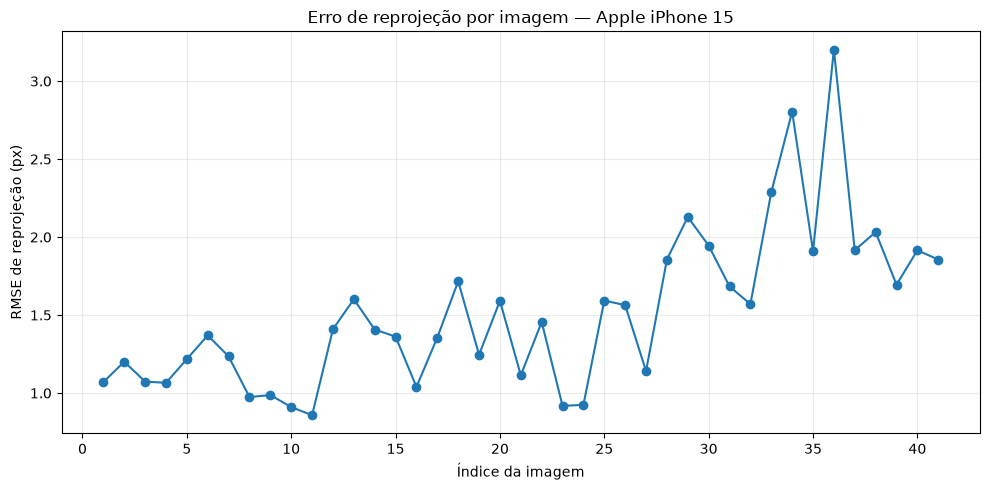

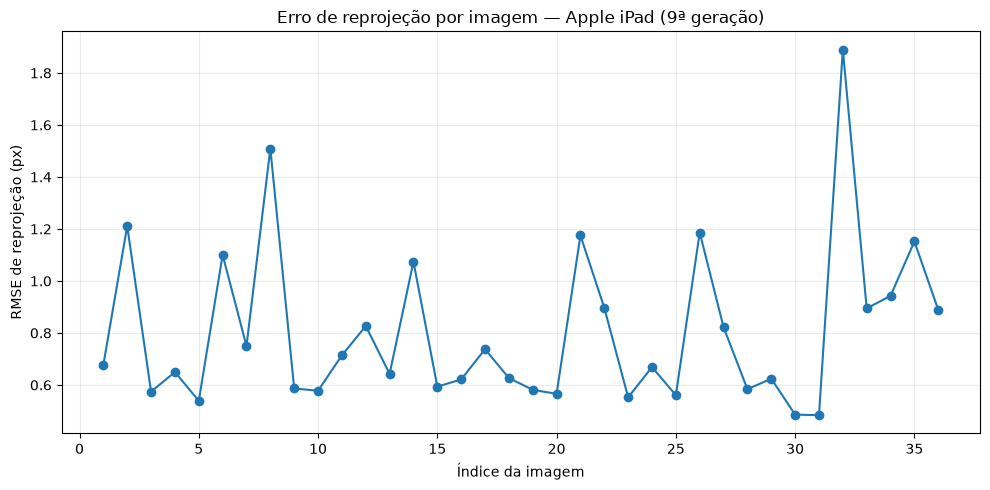

In [24]:
for camera_id, camera_name in CAMERAS.items():
    subset = (
        reprojection_df
        .loc[reprojection_df["camera_id"] == camera_id]
        .reset_index(drop=True)
    )

    plt.figure(figsize=(10, 5))
    plt.plot(
        np.arange(1, len(subset) + 1),
        subset["rmse_px"],
        marker="o",
    )
    plt.xlabel("Índice da imagem")
    plt.ylabel("RMSE de reprojeção (px)")
    plt.title(f"Erro de reprojeção por imagem — {camera_name}")
    plt.grid(True, alpha=0.25)
    plt.tight_layout()

    output_path = FIGURES_DIR / f"{camera_id}_reprojection_error.png"
    plt.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()

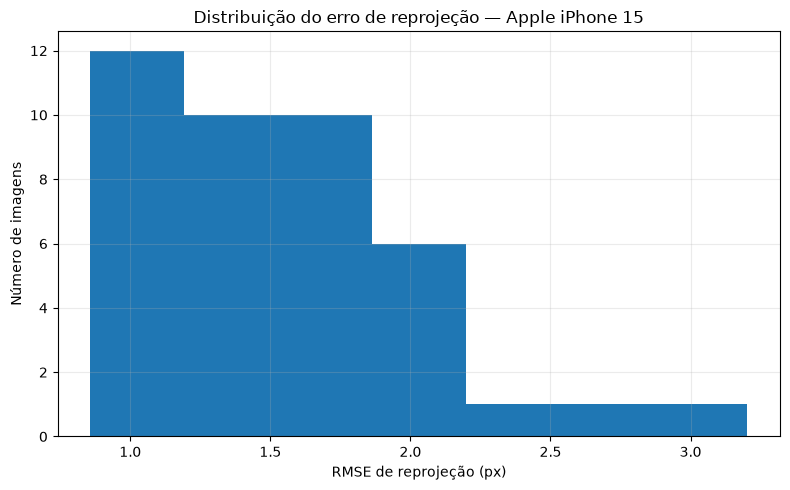

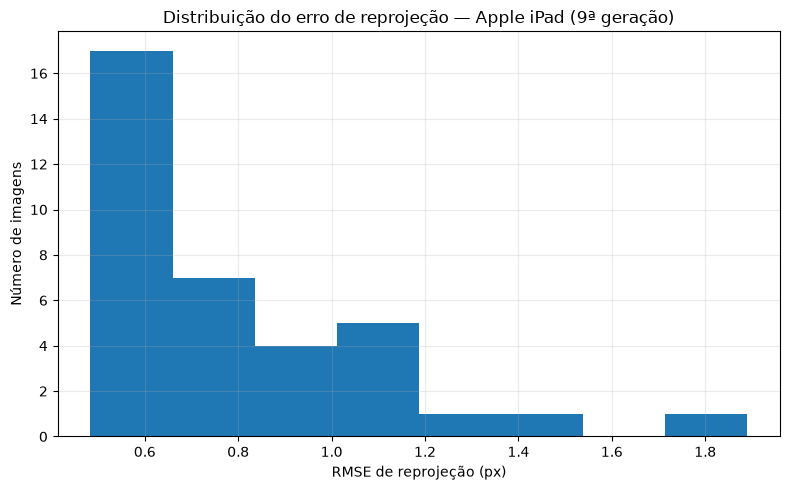

In [25]:
for camera_id, camera_name in CAMERAS.items():
    subset = reprojection_df.loc[
        reprojection_df["camera_id"] == camera_id,
        "rmse_px",
    ]

    plt.figure(figsize=(8, 5))
    plt.hist(subset, bins="auto")
    plt.xlabel("RMSE de reprojeção (px)")
    plt.ylabel("Número de imagens")
    plt.title(f"Distribuição do erro de reprojeção — {camera_name}")
    plt.grid(True, alpha=0.25)
    plt.tight_layout()

    output_path = FIGURES_DIR / f"{camera_id}_reprojection_histogram.png"
    plt.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()

## 11. Exportação dos resultados

Para cada câmera, o arquivo JSON registra:

- solução fechada dos parâmetros intrínsecos;
- valores iniciais de $k_1,k_2$;
- parâmetros finais após Levenberg–Marquardt;
- parâmetros extrínsecos de cada vista;
- diagnóstico das homografias;
- erro de reprojeção por imagem.

Também são geradas tabelas CSV para facilitar a análise e a utilização dos resultados nos demais experimentos.

In [26]:
def as_list(value):
    return np.asarray(value, dtype=float).tolist()


def calibration_to_json(
    calibration: dict,
) -> dict:
    camera_id = calibration["camera_id"]

    image_errors = (
        reprojection_df
        .loc[reprojection_df["camera_id"] == camera_id]
        .drop(columns=["camera_id", "camera"])
        .to_dict(orient="records")
    )

    return {
        "method": {
            "name": "Zhang camera calibration",
            "reference": (
                "Z. Zhang, A Flexible New Technique for Camera "
                "Calibration, MSR-TR-98-71"
            ),
        },
        "camera_id": camera_id,
        "camera": calibration["camera_name"],
        "image_resolution_px": {
            "width": int(calibration["image_size"][0]),
            "height": int(calibration["image_size"][1]),
        },
        "calibration_pattern": {
            "type": "planar chessboard",
            "inner_corners": {
                "columns": int(PATTERN_SIZE[0]),
                "rows": int(PATTERN_SIZE[1]),
            },
            "square_size_mm": float(SQUARE_SIZE_MM),
        },
        "images": {
            "discovered": int(len(calibration["entries"])),
            "used": int(len(calibration["valid_entries"])),
        },
        "closed_form_solution": {
            "camera_matrix": as_list(
                calibration["A_closed_form"]
            ),
            "intrinsics": calibration["intrinsics_closed_form"],
            "b": as_list(calibration["b"]),
            "V_singular_values": as_list(
                calibration["V_singular_values"]
            ),
        },
        "initial_radial_distortion": {
            "k1": float(calibration["k_initial"][0]),
            "k2": float(calibration["k_initial"][1]),
        },
        "maximum_likelihood_refinement": {
            "success": bool(
                calibration["optimization_result"].success
            ),
            "message": str(
                calibration["optimization_result"].message
            ),
            "nfev": int(
                calibration["optimization_result"].nfev
            ),
            "camera_matrix": as_list(
                calibration["A_refined"]
            ),
            "intrinsics": {
                "alpha": float(calibration["A_refined"][0, 0]),
                "beta": float(calibration["A_refined"][1, 1]),
                "gamma": float(calibration["A_refined"][0, 1]),
                "u0": float(calibration["A_refined"][0, 2]),
                "v0": float(calibration["A_refined"][1, 2]),
            },
            "radial_distortion": {
                "k1": float(calibration["k_refined"][0]),
                "k2": float(calibration["k_refined"][1]),
            },
            "initial_global_rmse_px": float(
                calibration["initial_global_rmse_px"]
            ),
            "final_global_rmse_px": float(
                calibration["final_global_rmse_px"]
            ),
        },
        "extrinsics_refined": [
            {
                "file": entry["path"].name,
                "rotation_matrix": as_list(R),
                "translation_mm": as_list(t),
            }
            for entry, R, t in zip(
                calibration["valid_entries"],
                calibration["rotations_refined"],
                calibration["translations_refined"],
            )
        ],
        "homography_diagnostics": (
            calibration["homography_diagnostics"]
            .to_dict(orient="records")
        ),
        "per_image_reprojection_error": image_errors,
        "environment": {
            "python": platform.python_version(),
            "opencv": cv2.__version__,
            "numpy": np.__version__,
            "pandas": pd.__version__,
        },
    }


for camera_id, calibration in calibrations.items():
    output_path = CALIBRATION_DIR / f"{camera_id}.json"

    with output_path.open("w", encoding="utf-8") as file:
        json.dump(
            calibration_to_json(calibration),
            file,
            indent=2,
            ensure_ascii=False,
        )

    print(f"Salvo: {output_path.relative_to(ROOT)}")


calibration_summary_df.to_csv(
    TABLES_DIR / "calibration_summary.csv",
    index=False,
)

reprojection_df.to_csv(
    TABLES_DIR / "reprojection_errors.csv",
    index=False,
)

detection_df.to_csv(
    TABLES_DIR / "detection_summary.csv",
    index=False,
)

homography_tables = []

for calibration in calibrations.values():
    table = calibration["homography_diagnostics"].copy()
    table.insert(0, "camera_id", calibration["camera_id"])
    table.insert(1, "camera", calibration["camera_name"])
    homography_tables.append(table)

pd.concat(
    homography_tables,
    ignore_index=True,
).to_csv(
    TABLES_DIR / "homography_diagnostics.csv",
    index=False,
)

Salvo: results/calibration/iphone15.json
Salvo: results/calibration/ipad9.json


## 12. Verificação final dos artefatos

In [27]:
expected_outputs = [
    CALIBRATION_DIR / "iphone15.json",
    CALIBRATION_DIR / "ipad9.json",
    TABLES_DIR / "calibration_summary.csv",
    TABLES_DIR / "reprojection_errors.csv",
    TABLES_DIR / "detection_summary.csv",
    TABLES_DIR / "homography_diagnostics.csv",
    FIGURES_DIR / "iphone15_reprojection_error.png",
    FIGURES_DIR / "ipad9_reprojection_error.png",
    FIGURES_DIR / "iphone15_reprojection_histogram.png",
    FIGURES_DIR / "ipad9_reprojection_histogram.png",
]

output_status_df = pd.DataFrame([
    {
        "file": str(path.relative_to(ROOT)),
        "exists": path.exists(),
    }
    for path in expected_outputs
])

display(output_status_df)

if not output_status_df["exists"].all():
    raise RuntimeError(
        "Um ou mais artefatos esperados não foram produzidos."
    )

print("Procedimento de calibração concluído.")

,file,exists
0,results/calibration/iphone15.json,True
1,results/calibration/ipad9.json,True
2,results/tables/calibration_summary.csv,True
3,results/tables/reprojection_errors.csv,True
4,results/tables/detection_summary.csv,True
5,results/tables/homography_diagnostics.csv,True
6,results/figures/iphone15_reprojection_error.png,True
7,results/figures/ipad9_reprojection_error.png,True
8,results/figures/iphone15_reprojection_histogra...,True
9,results/figures/ipad9_reprojection_histogram.png,True


Procedimento de calibração concluído.


## 13. Síntese do procedimento

O processamento executado pode ser resumido por:

$$
\begin{gathered}
\text{correspondências } M_j \leftrightarrow m_{ij} \\
\downarrow \\
H_1, H_2, \ldots, H_n \\
\downarrow \\
Vb = 0 \\
\downarrow \\
A, \; R_i, \; t_i \\
\downarrow \\
Dk = d \quad\Rightarrow\quad k_1, k_2 \\
\downarrow \\
\min \sum_{i,j} \left\| m_{ij} - \breve m(A, k_1, k_2, R_i, t_i, M_j) \right\|^2.
\end{gathered}
$$

A matriz intrínseca final, os coeficientes de distorção radial e os parâmetros extrínsecos resultam do refinamento conjunto da Equação (14).